<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/02%20-%20Supervised%20Learning/020_ml_for_materials_overview.ipynb)

# 020 · 机器学习与材料科学总概论：从数据表征到智能发现

在第一模块（`01a`–`01d`）中，我们已经攒齐了材料数据科学的基本功：用 Python 和 Pandas 清洗近万条真实实验数据，用 Matplotlib 绘制科研图表，并用 RDKit 把有机半导体分子结构（SMILES）翻译成计算机能读懂的 **17 个物理化学描述符**与 **2048 维分子指纹**。

但在一头扎进具体的回归与分类算法之前，我们先停下来退后一步，把整门课的“全景作战地图”铺开，回答两个最核心的问题：
1. **到底什么是机器学习？** 它和材料人熟悉的“炒菜试错实验、热力学经验公式、第一性原理计算（DFT）”究竟是什么关系？
2. **机器学习在材料科学里到底能干什么、不能干什么？** 面对不同的课题需求，该选哪类算法？材料数据又有哪些互联网 AI 从未遇到过的“专属大坑”？

> **⏱️ 建议学习时间**：30–40 分钟（通读概念脉络 + 运行并修改 4 个轻量可视化互动实验）。

### 本节内容
1. 为什么材料科学需要机器学习？（四大研发范式与化学空间爆炸）
2. 到底什么是机器学习？（AI $\supset$ ML $\supset$ DL 与从“写公式”到“学规律”的反转）
3. 机器学习在材料科学里能用在哪？（五大核心任务 $\leftrightarrow$ 全课程 02–10 模块地图）
4. 材料信息学 $\neq$ 互联网 AI：进实验室前必须牢记的五大“专属陷阱”
5. 规范的材料 ML 项目六步闭环与个人课题选型自测

In [1]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "02 - Supervised Learning"))


## 0. 环境准备与绘图风格加载

本节所有互动实验仅依赖标准科学计算库（`numpy`、`pandas`、`matplotlib`、`scikit-learn`），本地与 Google Colab 均可秒级运行：

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

print("Environment ready!")

Environment ready!


<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [3]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


---
## 1. 为什么材料科学需要机器学习？

### 📘 1.1 材料四面体与科学研究四大范式

材料科学的核心使命，是在**工艺（Processing）— 结构（Structure）— 性质（Properties）— 服役性能（Performance）**的四面体中建立定量桥梁：既希望能“给定结构预测性质（正向问题）”，更希望能“给定目标性能倒推最佳成分与工艺（逆向问题）”。

回顾过去几百年，人类探索新材料经历了四种互补的研究范式：

| 范式 | 代表方法 | 核心优势 | 现实瓶颈 |
| :--- | :--- | :--- | :--- |
| **第一范式：实验试错** | 爱迪生式筛选、正交实验 | 结果真实可靠，直接检验可合成性与器件表现 | 周期极长（合成+表征常需数天至数周），前驱体与设备昂贵 |
| **第二范式：理论与经验方程** | 热力学定律、`01c` 中的 $E_{\text{gap}} = a + b/N$、Yalkowsky 溶解度方程 | 物理图像清晰，形式简洁，在适用范围内具备良好外推性 | 面对多组分、多尺度非平衡耦合体系时，很难写出解析公式 |
| **第三范式：计算模拟** | 密度泛函理论（DFT）、分子动力学（MD）、相场与有限元 | 无需买试剂即可从原子尺度预测电子结构与热力学稳定性 | 受限于量子力学 $O(N_e^3)$ 标度墙：算准一个百原子晶胞或激发态往往耗时数小时至数天 |
| **第四范式：数据驱动（AI4M）** | 统计机器学习、贝叶斯主动寻优、图神经网络与生成模型 | 训练完成后**毫秒级推理**，擅长在高维复杂数据中捕捉非线性映射 | 严重依赖数据质量与表征选择；**不是取代物理，而是与实验和计算协同** |

> **💡 破除一个常见误解**：机器学习并不会“淘汰”物理化学理论或 DFT 计算。在现代材料研发中，它最核心的角色有两个：
> 1. **高速代理模型（Surrogate Model）**：在百万级虚拟分子/晶体库中先用毫秒级 ML 筛掉 99.9% 的劣质候选，只留几十个最有希望的苗头交给 DFT 精算和湿实验验证（**漏斗式筛选**）；
> 2. **昂贵实验空间的导航仪**：当全空间根本测不完时，根据已有几十组实验结果动态推荐“下一锅最值得做的配方”。

### 🤔 先猜一猜：你的实验空间到底有多大？

假设你要设计一种**给体–$\pi$桥–受体（D–$\pi$–A）有机光电小分子**：候选库里有 40 种给体单元（D）、25 种共轭桥（$\pi$）、40 种受体单元（A）和 12 种增溶侧链，再搭配 5 种旋涂溶剂和 4 种退火温度。如果实验室每周能合成并表征 10 个样品，把所有组合试完大概需要几个月、几年，还是几万年？

运行下面这格代码算一笔账，并看看材料空间的真实量级（你也可以修改 `# ✏️` 处的数字换成你自己的课题参数）：

仅 D-π-A-侧链 分子结构组合数：480,000 种
计入旋涂与退火工艺后的总实验组合：9,600,000 种 (~10^7.0)
按每周完成 8 组实验计算，全部试完需要：23,077 年！


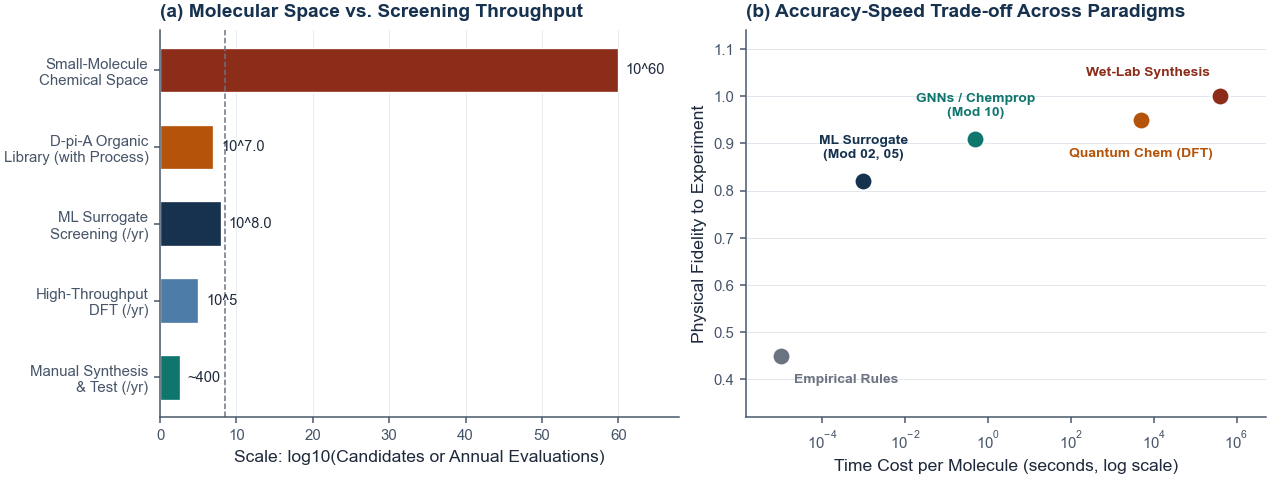

In [4]:
# ▶️ 运行看看 / ✏️ 改一改：换成你课题里的分子设计与工艺维度
n_donors = 40             # ✏️ 候选给体单元 (Donor) 数量
n_bridges = 25            # ✏️ 候选共轭桥 (pi-bridge) 数量
n_acceptors = 40          # ✏️ 候选受体单元 (Acceptor) 数量
n_sidechains = 12         # ✏️ 候选增溶侧链种类数
n_process_conds = 5 * 4   # ✏️ 5 种旋涂溶剂 × 4 种退火温度
weekly_experiments = 8    # ✏️ 课题组每周能合成+提纯+测完器件的分子数

mol_combinations = n_donors * n_bridges * n_acceptors * n_sidechains
total_combinations = mol_combinations * n_process_conds
years_needed = total_combinations / (weekly_experiments * 52)

print(f"仅 D-π-A-侧链 分子结构组合数：{mol_combinations:,} 种")
print(f"计入旋涂与退火工艺后的总实验组合：{total_combinations:,} 种 (~10^{np.log10(total_combinations):.1f})")
print(f"按每周完成 {weekly_experiments} 组实验计算，全部试完需要：{years_needed:,.0f} 年！")

# 可视化：(a) 候选分子空间 vs 筛选通量（对数尺度）；(b) 多范式速度—精度权衡
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.6, 4.0))

labels = [
    "Manual Synthesis\n& Test (/yr)",
    "High-Throughput\nDFT (/yr)",
    "ML Surrogate\nScreening (/yr)",
    "D-pi-A Organic\nLibrary (with Process)",
    "Small-Molecule\nChemical Space",
]
log_counts = [2.6, 5.0, 8.0, np.log10(total_combinations), 60.0]
bar_colors = [C.teal, C.steel, C.navy, C.gold, C.crimson]

bars = ax1.barh(labels, log_counts, color=bar_colors, height=0.58)
ax1.axvline(8.5, color=C.slate, linestyle="--", linewidth=0.9)
ax1.set_xlabel("Scale: log10(Candidates or Annual Evaluations)")
ax1.set_title("(a) Molecular Space vs. Screening Throughput")
ax1.set_xlim(0, 68)
ax1.grid(axis="x", alpha=0.45)
ax1.grid(axis="y", visible=False)
for bar, val in zip(bars, log_counts):
    txt = f"10^{val:.1f}" if 6 < val < 15 else (f"10^{val:.0f}" if val >= 3 else "~400")
    ax1.text(val + 1.0, bar.get_y() + bar.get_height() / 2, txt,
             va="center", fontsize=8.8, color=C.ink)

stages = [
    ("Empirical Rules", 1e-5, 0.45, C.slate, (8, -16), "left"),
    ("ML Surrogate\n(Mod 02, 05)", 1e-3, 0.82, C.navy, (0, 14), "center"),
    ("GNNs / Chemprop\n(Mod 10)", 5e-1, 0.91, C.teal, (0, 14), "center"),
    ("Quantum Chem (DFT)", 5e3, 0.95, C.gold, (0, -22), "center"),
    ("Wet-Lab Synthesis", 4e5, 1.00, C.crimson, (-6, 12), "right"),
]
for name, sec_per_eval, rel_fidelity, col, offset, align in stages:
    ax2.scatter(sec_per_eval, rel_fidelity, s=115, color=col, zorder=4, edgecolors="white", linewidth=1.2)
    ax2.annotate(name, (sec_per_eval, rel_fidelity), xytext=offset,
                 textcoords="offset points", ha=align, fontsize=8.3, color=col, fontweight="bold")

ax2.set_xscale("log")
ax2.set_xlim(1.5e-6, 5e6)
ax2.set_ylim(0.32, 1.14)
ax2.set_xlabel("Time Cost per Molecule (seconds, log scale)")
ax2.set_ylabel("Physical Fidelity to Experiment")
ax2.set_title("(b) Accuracy-Speed Trade-off Across Paradigms")

plt.show()

---
## 2. 到底什么是机器学习？

### 📘 2.1 先分清三个常被混用的词：AI $\supset$ ML $\supset$ DL

在文献和组会汇报里，人工智能（AI）、机器学习（ML）和深度学习（DL）经常被混着说，它们其实是层层包含的同心圆：
- **人工智能（Artificial Intelligence, AI）**：最宽泛的目标——让计算机执行通常需要人类智慧的任务（包括早期的专家规则库，比如写几百条 `if-else` 判断官能团毒性，也属于 AI，但它**不是**机器学习）。
- **机器学习（Machine Learning, ML）**：AI 的核心子集——**不靠人类手工写死转换公式，而是让算法直接从数据样本中自动归纳统计规律**（线性回归、k 近邻、随机森林、高斯过程都属于经典机器学习，是课程上半学期 `02`–`06` 的主角）。
- **深度学习（Deep Learning, DL）**：机器学习的一个分支——利用多层人工神经网络自动从原始图像、序列或分子图中提取多层次特征表示（CNN、Transformer、VAE、GNN 属于深度学习，是课程下半学期 `07`–`10` 的主角）。

### 📘 2.2 核心思维反转：从“带入公式算结果”到“喂入结果学公式”

把你在 `01a`–`01d` 写过的代码与即将开始的机器学习对比，本质上发生了一次**输入与输出的反转**：

$$
\begin{aligned}
\textbf{传统科学计算 / 经验方程：} & \quad \text{材料输入 } X \; + \; \text{已知物理公式 } f \; \longrightarrow \; \text{算出性质 } y \\[6pt]
\textbf{机器学习（以监督学习为例）：} & \quad \text{材料输入 } X \; + \; \text{实测性质标签 } y \; \longrightarrow \; \text{自动学出近似映射 } \hat{f}(X) \approx y
\end{aligned}
$$

所谓的“**模型训练（Training / Fitting）**”，没有任何神秘色彩：模型内部有一组可调节的参数 $\theta$（比如线性方程的斜率权重，或决策树的分裂阈值）；计算机先猜一组初值，对比预测值 $\hat{y} = \hat{f}_\theta(X)$ 与真实实验值 $y$ 之间的差距（**损失函数 Loss**），然后自动调整 $\theta$ 让误差尽可能变小。训练完成后，遇到从未合成过的新分子 $X_{\text{new}}$，直接算出 $\hat{f}_\theta(X_{\text{new}})$ 即可完成**推理（Inference）**。

### ▶️ 运行看看：用真实的 AqSolDB 水溶解度数据直观感受“三次跃迁”

先不用深究下面的 `scikit-learn` 语法（下一节 `02a` 会逐行拆解），我们先在第一部分清洗过的 **AqSolDB 数据集**上直观对比预测水溶解度 $\log S$ 的三种层次：
1. **单变量经验直觉**：只看油水分配系数 `MolLogP`（越疏水越难溶，一条直线）；
2. **多特征线性组合**：同时考虑分子量、极性表面积、氢键给受体、芳香环数等全部 17 个物理化学描述符，但假设它们只是简单线性相加；
3. **非线性机器学习（随机森林）**：同样用这 17 个描述符，允许模型自动捕捉特征之间的非线性交互（例如“大共轭稠环 + 柔性极性基团”的协同效应）。

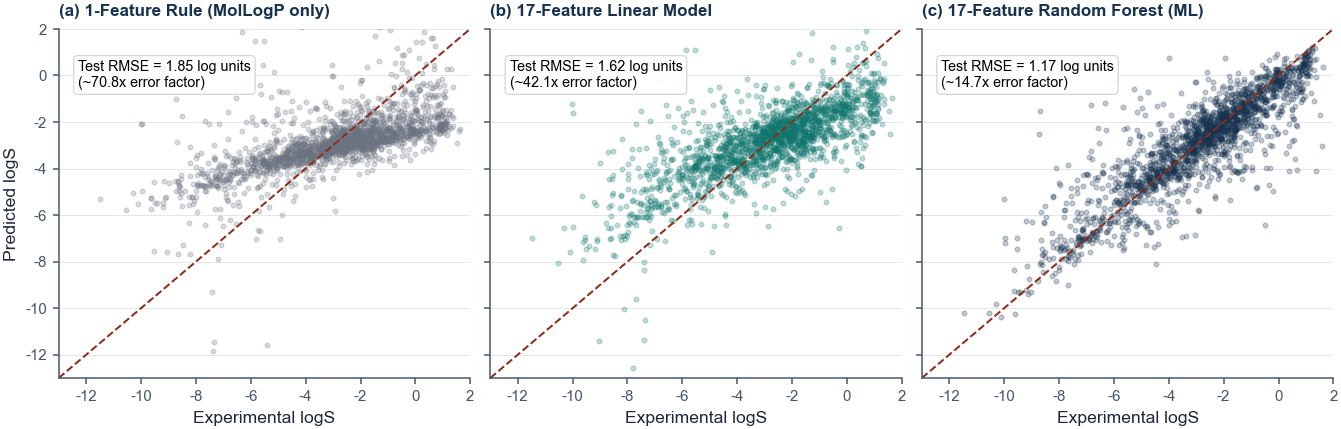

In [5]:
# ▶️ 运行看看：在留出的未见测试分子上对比三种预测精度
data_path = "data/solubility.csv" if os.path.exists("data/solubility.csv") else "../01 - Basics/data/solubility.csv"
df_sol = pd.read_csv(data_path)

feature_cols = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
    "BalabanJ", "BertzCT",
]
df_sol = df_sol.dropna(subset=feature_cols + ["Solubility"]).reset_index(drop=True)

X_all = df_sol[feature_cols].values
y_all = df_sol["Solubility"].values

# 按 8:2 切分：80% 给机器“平时刷题学习”，留 20% 藏起来当“期末闭卷考题”
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
logp_idx = feature_cols.index("MolLogP")

# 层次 1：仅靠 MolLogP 单变量经验直线
m1 = LinearRegression().fit(X_tr[:, [logp_idx]], y_tr)
pred_1 = m1.predict(X_te[:, [logp_idx]])

# 层次 2：17 个描述符多元线性回归
m2 = LinearRegression().fit(X_tr, y_tr)
pred_2 = m2.predict(X_te)

# 层次 3：17 个描述符非线性随机森林
m3 = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
pred_3 = m3.predict(X_te)

fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.6), sharex=True, sharey=True)
configs = [
    ("(a) 1-Feature Rule (MolLogP only)", pred_1, C.slate),
    ("(b) 17-Feature Linear Model", pred_2, C.teal),
    ("(c) 17-Feature Random Forest (ML)", pred_3, C.navy),
]

for ax, (title, y_pred, col) in zip(axes, configs):
    rmse = root_mean_squared_error(y_te, y_pred)
    ax.scatter(y_te, y_pred, s=8, alpha=0.25, color=col, rasterized=True)
    ax.plot([-13, 2], [-13, 2], "--", color=C.crimson, linewidth=1.2, label="Ideal y = x")
    ax.set_xlim(-13, 2)
    ax.set_ylim(-13, 2)
    ax.set_xlabel("Experimental logS")
    ax.set_title(title, fontsize=10.2)
    ax.text(
        -12.3, -0.5, f"Test RMSE = {rmse:.2f} log units\n(~{10**rmse:.1f}x error factor)",
        fontsize=8.6, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=C.muted, alpha=0.92),
    )

axes[0].set_ylabel("Predicted logS")
plt.show()

> **💡 读图要点**：上图叫做**对角线图（Parity Plot）**，是整门课出现频率最高的一张诊断图。如果预测完美，所有点都会落在红色虚线 $y = x$ 上。可以看到，单靠 `MolLogP` 一条直线时散点云非常宽；引入 17 个物理化学特征并允许树模型捕捉非线性交互后，散点显著向对角线收拢，未见测试分子上的预测误差大幅下降。

---
## 3. 机器学习在材料科学里能干什么？（五大核心场景与课程全景图）

“机器学习”不是一把锤子，而是一整箱各司其职的工具。根据**你手头的数据有没有性质标签（$y$）**以及**你想解决正向预测、实验寻优还是逆向生成问题**，材料科学中的 AI 应用可以清晰地划分为五大范式——它们恰好对应本课程接下来的第 `02` 至 `10` 模块：

| 范式类别 | 核心科学问题 | 输入与输出 | 材料科学典型案例 | 本课程对应模块 |
| :--- | :--- | :--- | :--- | :--- |
| **① 监督学习**<br>*(Supervised Learning)* | **“给定材料结构或工艺，它的性质是多少 / 属于哪一类？”** | 有标签数据 $(X, y) \to$ 预测连续值（**回归**）或离散类别（**分类**） | 预测有机半导体溶解度 $\log S$、晶体形成能 $E_f$、带隙；筛查候选物是否可溶、是否热力学稳定 | **`02` 监督学习与防坑**<br>**`05` 特征工程与 SHAP**<br>**`06` 晶体材料信息学** |
| **② 无监督学习**<br>*(Unsupervised Learning)* | **“这几千种材料没有性质标签，它们在化学空间里分几大家族？有没有反常特例？”** | 仅有特征 $X$（无 $y$）$\to$ **降维可视化**或**聚类分组** | 绘制配体/分子化学空间地图（PCA/t-SNE）；从高维指纹中聚类发现新型双核钯催化剂（*Science* 复现） | **`03` 无监督学习：化学空间与发现** |
| **③ 贝叶斯优化与主动学习**<br>*(Bayesian Optimization)* | **“合成一锅材料要三天，手里只有 15 组数据，下一锅做哪个配方最可能刷新纪录？”** | 少量历史实验 $(X, y) \to$ 输出**预测均值 + 不确定性**，推荐下一个实验点 | 钙钛矿旋涂退火工艺寻优、钯催化偶联反应收率最大化（兼顾“去高分区域深挖”与“去未知区域探路”） | **`04` 贝叶斯优化与主动实验设计** |
| **④ 深度视觉与序列模型**<br>*(CNNs & Transformers)* | **“如何自动解析电镜图像与谱图？如何像读句子一样读懂化学反应式？”** | 原始二维图像或一维 SMILES 字符串 $\to$ 自动提取表征并预测 | SEM/金相显微组织自动分类、低剂量电镜图像去噪与超分辨；SMILES 语言模型异常检测与偶联反应产物预测 | **`07` 神经网络与显微 CNN**<br>**`08` 序列模型与 Transformer**<br>**`09c` 电镜超分与扩散模型** |
| **⑤ 生成模型、图网络与机器学习势函数**<br>*(Generative AI, GNNs & MLIPs)* | **“能否按目标性质直接生成新分子？能否直接以 3D 原子图达到近 DFT 精度的动力学模拟？”** | 目标性质 $y^* \to$ **逆向生成新结构**；或分子/晶体图 $\mathcal{G} \to$ 能量 $E$ 与原子受力 $\mathbf{F}$ | 基于 SELFIES VAE 的分子定向生成；分子/晶体消息传递图网络（D-MPNN / CGCNN）与 MACE 原子间势函数 | **`09a–b` 分子生成模型**<br>**`10` 图神经网络与 MLIPs** |

> **💡 一句话记住上下半学期的分工**：
> - **上半学期（`01`–`06`）**：当我们用物理化学专业知识把材料整理成一张**结构化特征表格**时，**树模型集成（RF/XGBoost）+ 高斯过程（GPR）+ SHAP 归因**依然是当今实验室小样本数据上最稳健、最高效的主力武器；
> - **下半学期（`07`–`10`）**：当输入是**显微图像、反应序列、3D 原子坐标图**，或者需要**从零生成新结构**时，手工提取表格特征不再够用，以 PyTorch 构建的**深度表征学习**正式登场。

---
## 4. 材料信息学 $\neq$ 互联网 AI：进实验室前必知的五大“专属陷阱”

很多初学者照搬互联网教程（猫狗图像分类、房价预测）的代码去发材料论文，结果审稿人一眼看出漏洞，或者模型推荐出来的“神级配方”进实验室一做全军覆没。这是因为**材料科学的数据生态与互联网大数据有着本质差异**：

1. **小样本与高异质噪声（Small & Heterogeneous Data）**
   - 互联网大模型动辄训练 $10^7\text{–}10^{12}$ 个样本；而在材料课题中，能攒出 $10^2\text{–}10^3$ 条同口径实验数据就已经非常珍贵，文献拼凑的数据还常混杂着不同实验室的温度、纯度与测试误差。
   - **实战推论**：在样本量 $N < 10^3$ 时，盲目套用几百万参数的深度神经网络极易死记硬背噪声；**高质量的物理化学描述符（`01d`/`05`/`06`）配合传统机器学习往往表现更好**。
2. **最致命的矛盾：机器学习擅长“内插”，而材料学家渴望“外推”**
   - 人脸识别只要求认出和训练集分布一致的照片（**内插 Interpolation**）；但材料研发的终极目标是找到**比训练集里所有已知材料迁移率更高、催化活性更强、工作温度更高**的新记录（**外推 Extrapolation**）。
3. **同母核衍生物导致的“虚假高分”（Data Leakage & Scaffold Bias）**
   - 化学数据集里往往包含同一母核（比如噻吩或蒽）挂不同支链的几十个同系物。如果简单随机打乱切分训练/测试集，模型只要“认出眼熟的母核”就能在测试集考出 $R^2 = 0.95$ 的高分；一旦遇到全新母核就彻底失灵（我们将在 `02b` 用 **Scaffold Split 骨架划分**专门治这个病）。
4. **模型不会主动说“我不知道”（Lack of Uncertainty Awareness）**
   - 把一块无机陶瓷晶体的描述符塞进有机小分子溶解度模型里，普通神经网络或随机森林照样会面不改色地报出一个精确到小数点后四位的数字。因此材料 AI 必须配备**适用域诊断（`02b`）**或**不确定性误差棒（`04` 高斯过程、`07a` MC Dropout）**。
5. **统计相关性不等于物理因果（Correlation $\neq$ Causation）**
   - 如果训练集里所有含氟分子恰好都是某台新仪器在高温下测的，模型就会把“含氟”当成高温性能好的原因。建模后必须结合**特征重要性（`02c`）与 SHAP 归因（`05a`）**核对物理化学机制。

### 🤔 先猜一猜：当模型走出训练区边界会发生什么？

回到我们在 `01c` 见过的共轭分子体系（如低聚噻吩或并苯系列）的光学能隙规律：随着共轭环数 $N$ 增加，真实物理规律遵循渐近收敛关系 $E_{\text{gap}}(N) = E_\infty + b / N$。

假设实验室目前只合成出了小共轭分子 $N \in [1, 6]$（带一点测量噪声），我们用三种方法拟合并去预测从未合成过的大共轭分子 $N \in [7, 14]$：
- **5 阶多项式回归**（纯数学曲线拟合）
- **随机森林回归**（最常用的非线性树模型）
- **嵌入物理先验的线性模型**（以 $1/N$ 作为输入特征）

在运行下方代码前先猜一猜：**在 $N > 6$ 的未知区域，随机森林画出来的预测曲线会是什么形状？**

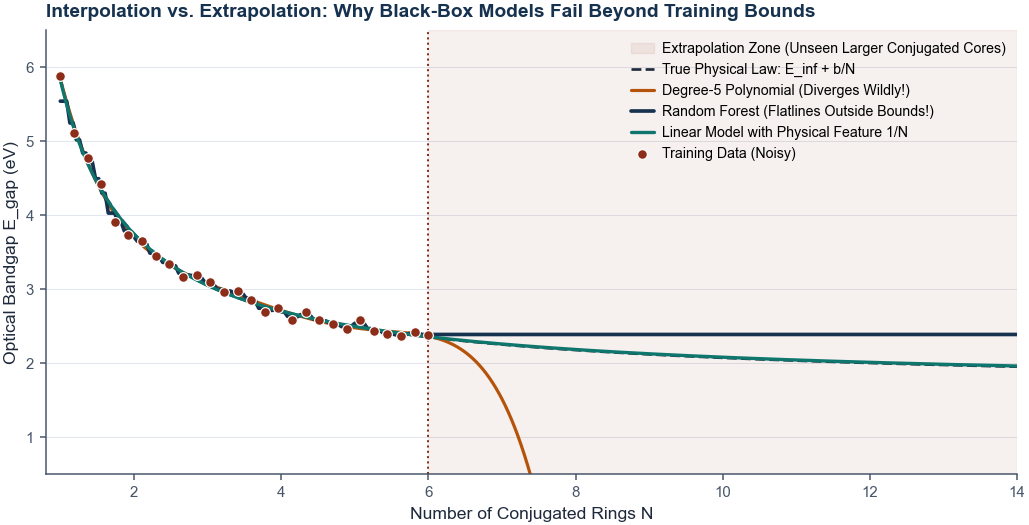

模型对比（对真实无噪物理曲线的 RMSE，单位 eV）：
  5阶多项式 | 训练区内插 RMSE = 0.025 eV  -->  未知区外推 RMSE = 248.865 eV
  随机森林   | 训练区内插 RMSE = 0.055 eV  -->  未知区外推 RMSE = 0.312 eV
  物理特征 1/N | 训练区内插 RMSE = 0.007 eV  -->  未知区外推 RMSE = 0.009 eV


In [6]:
# ▶️ 运行看看 / ✏️ 改一改：内插（Interpolation）很美，外推（Extrapolation）翻车现场
rng = np.random.default_rng(42)

n_max_train = 6          # ✏️ 试试改成 5 或 8，观察训练区覆盖范围对外推的影响
noise_std = 0.08         # ✏️ 试试改成 0.02 或 0.18，观察测量噪声对高阶多项式的破坏

# 真实物理规律（示意）：E_gap(N) = 1.65 + 4.20 / N (eV)
def true_egap(n):
    return 1.65 + 4.20 / n

# 训练数据：仅分布在短链区间 N in [1, n_max_train]
N_train = np.linspace(1.0, n_max_train, 28)
y_train = true_egap(N_train) + rng.normal(0, noise_std, size=len(N_train))

# 全区间网格：包含训练区 [1, n_max_train] 与未知外推区 (n_max_train, 14]
N_grid = np.linspace(1.0, 14.0, 300)
y_true_grid = true_egap(N_grid)

# 模型 1：5 阶多项式（缺乏物理约束的高自由度函数）
poly_model = make_pipeline(PolynomialFeatures(degree=5), LinearRegression())
poly_model.fit(N_train.reshape(-1, 1), y_train)
pred_poly = poly_model.predict(N_grid.reshape(-1, 1))

# 模型 2：随机森林（树集成代表，02a 的主力算法）
rf_model = RandomForestRegressor(n_estimators=150, random_state=42)
rf_model.fit(N_train.reshape(-1, 1), y_train)
pred_rf = rf_model.predict(N_grid.reshape(-1, 1))

# 模型 3：物理启发特征 1/N + 线性回归（Physics-Informed Feature Engineering）
phys_model = LinearRegression()
phys_model.fit((1.0 / N_train).reshape(-1, 1), y_train)
pred_phys = phys_model.predict((1.0 / N_grid).reshape(-1, 1))

fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.axvspan(n_max_train, 14.0, color=C.crimson, alpha=0.07, label="Extrapolation Zone (Unseen Larger Conjugated Cores)")
ax.axvline(n_max_train, color=C.crimson, linestyle=":", linewidth=1.2)

ax.plot(N_grid, y_true_grid, "--", color=C.ink, linewidth=1.6, label="True Physical Law: E_inf + b/N")
ax.plot(N_grid, pred_poly, color=C.gold, linewidth=1.9, label="Degree-5 Polynomial (Diverges Wildly!)")
ax.plot(N_grid, pred_rf, color=C.navy, linewidth=2.2, label="Random Forest (Flatlines Outside Bounds!)")
ax.plot(N_grid, pred_phys, color=C.teal, linewidth=2.0, label="Linear Model with Physical Feature 1/N")
ax.scatter(N_train, y_train, s=34, color=C.crimson, zorder=5, edgecolors="white", linewidth=0.7, label="Training Data (Noisy)")

ax.set_xlim(0.8, 14.0)
ax.set_ylim(0.5, 6.5)
ax.set_xlabel("Number of Conjugated Rings N")
ax.set_ylabel("Optical Bandgap E_gap (eV)")
ax.set_title("Interpolation vs. Extrapolation: Why Black-Box Models Fail Beyond Training Bounds")
ax.legend(loc="upper right", fontsize=8.5)

plt.show()

in_mask = N_grid <= n_max_train
out_mask = N_grid > n_max_train
print("模型对比（对真实无噪物理曲线的 RMSE，单位 eV）：")
for name, pred in [("5阶多项式", pred_poly), ("随机森林  ", pred_rf), ("物理特征 1/N", pred_phys)]:
    rmse_in = root_mean_squared_error(y_true_grid[in_mask], pred[in_mask])
    rmse_out = root_mean_squared_error(y_true_grid[out_mask], pred[out_mask])
    print(f"  {name} | 训练区内插 RMSE = {rmse_in:.3f} eV  -->  未知区外推 RMSE = {rmse_out:.3f} eV")

> **💡 记住这张图里的两个经典现象（后面做科研天天会遇到）**：
> 1. **多项式发散（金棕色曲线）**：在训练区内误差极小，一踏出 $N > 6$ 就剧烈发散——这就是过度灵活却毫无物理约束的模型在外推时的灾难。
> 2. **树模型水平截断（深海蓝曲线）**：随机森林的本质是把训练样本划分到各个“叶节点格子里求平均”，因此**它的预测值永远不可能超出训练集最小/最大标签的范围**！一旦 $N > 6$，它只能机械重复 $N = 6$ 附近的数值。下一节 `02a` 结尾当我们用随机森林预测大稠环并五苯（Pentacene）溶解度时，你会再次亲眼撞见这个“贴边失真”现象。
> 3. **把物理知识写进特征里（青绿色曲线）**：哪怕底层只是最简单的线性回归，只要输入了具备正确渐近物理意义的描述符 $1/N$，外推依然稳如泰山——这就是为什么本课程用整整三个模块（`01d`、`05`、`06`）认真打磨分子与晶体的特征表示。

---
## 5. 规范的材料机器学习六步闭环与课题选型自测

### 📘 5.1 从原始数据到真实实验验证的六步标准动作

无论你将来用最简单的线性回归，还是最前沿的图神经网络，一个经得起审稿人与实验室检验的材料 AI 项目都遵循同一套闭环：

1. **定义科学问题与数据口径**：明确输入材料表示 $X$、目标性质 $y$（或无监督/寻优目标），统一实验测试条件（温度、溶剂、表征标准）；
2. **数据清洗与领域表征（`01b`–`01d`）**：剔除解析失败或重复结构（Canonical SMILES / 晶体对称性去重），提取描述符、指纹或图结构；
3. **贴合应用场景的数据划分（`02a`、`02b`）**：严防数据泄漏（`Pipeline`），根据实际泛化需求选择随机划分、分层抽样或更严苛的骨架/组分外推划分（Scaffold / Composition Split）；
4. **先立傻瓜基线，再递进训练模型（`02a`、`02c`）**：永远先算一个“全猜均值/多数类”的零智商基线（Dummy Baseline），再按“线性模型 $\to$ 距离/核模型 $\to$ 树集成 $\to$ 深度学习”由简入繁对比；
5. **不确定性量化与适用域诊断（`02b`、`04`）**：评估新候选材料离训练数据有多远（Applicability Domain），拒绝盲目相信分布外的裸预测值；
6. **物理化学归因与实验闭环（`02c`、`04`、`05a`）**：检查模型看重的特征是否符合化学常识，把筛出的候选材料送回 DFT 或湿实验验证，并将新测数据（**尤其是失败的负样本！**）回流扩充数据集。

### ✏️ 改一改：给你的研究生课题匹配 AI 路线

把下面代码格里的 3 个变量改成你手头正在做（或打算做）的课题情况，运行看看应该优先从本课程的哪几个模块切入：

In [7]:
# ✏️ 改一改：填入你自己的科研课题画像
my_sample_size = 45             # ✏️ 你手头已有（或能从文献/数据库拿到的）样本数量，如 30, 800, 15000
has_property_labels = True      # ✏️ 每个样本是否带有明确的性能/性质数值或成败标签？(True / False)
my_research_goal = "optimize"   # ✏️ 可选: "predict" (性质预测/快筛) | "optimize" (少样本工艺/配方寻优)
                                #          "explore" (化学空间分类/找规律) | "image_or_seq" (电镜图像/反应序列)
                                #          "inverse_design" (按目标生成新分子/原子级势函数)

def recommend_ai4m_route(n: int, labeled: bool, goal: str) -> None:
    print("=" * 68)
    print(f"📋 课题诊断输入：样本量 N = {n} | 有无标签 = {labeled} | 核心目标 = '{goal}'")
    print("-" * 68)

    if not labeled or goal == "explore":
        print("🧭 推荐路线：【无监督学习：降维可视化 + 聚类分析】")
        print("  • 首选工具：PCA / t-SNE 化学空间映射 + K-means / DBSCAN / Butina 聚类")
        print("  • 对应模块：Module 03（无监督学习：化学空间与发现）")
        print("  • 防坑提醒：距离计算前务必做特征标准化；t-SNE 簇间远近不代表真实全局距离。")
        return

    if goal == "optimize" or n < 80:
        print("🧭 推荐路线：【小样本主动学习 / 贝叶斯优化闭环】")
        print("  • 首选工具：高斯过程回归（GPR，天然带不确定性误差棒）+ EI/UCB 采集函数")
        print("  • 对应模块：Module 02（交叉验证基础） -> Module 04（贝叶斯优化与主动实验设计）")
        print("  • 防坑提醒：样本少于 100 条时切忌硬上深度神经网络；精选 5–15 个核心物理化学特征最稳健！")
        return

    if goal == "image_or_seq":
        print("🧭 推荐路线：【材料视觉 CNN / 化学语言序列模型】")
        print("  • 首选工具：预训练/轻量 CNN（显微图像）、SMILES LSTM / Transformer（序列与反应）")
        print("  • 对应模块：Module 07（神经网络与显微 CNN）、Module 08（序列模型与 Transformer）、Module 09c")
        print("  • 防坑提醒：同一块样品切出的多张局部电镜图绝不能同时分进训练集和测试集（防空间泄漏）！")
        return

    if goal == "inverse_design":
        print("🧭 推荐路线：【生成模型与图神经网络 / 机器学习势函数】")
        print("  • 首选工具：SELFIES VAE + 代理模型定向寻优；或 Chemprop D-MPNN / CGCNN / MACE")
        print("  • 对应模块：Module 09（生成模型）与 Module 10（图神经网络与 MLIPs）")
        print("  • 防坑提醒：警惕生成器钻代理模型的空子（对抗欺骗），生成结果必须受适用域与可合成性约束！")
        return

    # 默认 goal == "predict"
    if n < 2000:
        print("🧭 推荐路线：【物理化学特征工程 + 经典树集成模型 + SHAP 可解释性】")
        print("  • 首选工具：RDKit/Pymatgen 描述符 + 随机森林 / XGBoost + K 折交叉验证 + SHAP")
        print("  • 对应模块：Module 02（监督学习） -> Module 05（特征工程与 SHAP） / Module 06（晶体信息学）")
    else:
        print("🧭 推荐路线：【经典树模型强基线 PK 端到端图神经网络（GNN）】")
        print("  • 首选工具：先跑 Module 02 的随机森林/XGBoost 建立强基线，再上 Module 10 的 Chemprop / CGCNN")
        print("  • 对应模块：Module 02 -> Module 05/06 -> Module 10（全课程模型大比拼）")
    print("  • 防坑提醒：务必使用 Scaffold Split / 组分外推划分检验模型面对全新材料家族时的真实泛化力！")

recommend_ai4m_route(my_sample_size, has_property_labels, my_research_goal)

📋 课题诊断输入：样本量 N = 45 | 有无标签 = True | 核心目标 = 'optimize'
--------------------------------------------------------------------
🧭 推荐路线：【小样本主动学习 / 贝叶斯优化闭环】
  • 首选工具：高斯过程回归（GPR，天然带不确定性误差棒）+ EI/UCB 采集函数
  • 对应模块：Module 02（交叉验证基础） -> Module 04（贝叶斯优化与主动实验设计）
  • 防坑提醒：样本少于 100 条时切忌硬上深度神经网络；精选 5–15 个核心物理化学特征最稳健！


---
## 小结与本章路线图（`02a`–`02f`）

到这里，你手里已经同时握住了两样东西：第一模块打磨好的**分子数值特征（燃料）**，以及本节建立起来的**材料机器学习全景地图与防坑守则（指南针）**。

为了不把机器学习学成“只会调 `fit/predict` 的黑箱”，本章接下来将把所有经典监督学习算法的**底层几何/数学直觉**与 **AqSolDB / 有机半导体真实分子实例**一一打通：
- **`02a` 线性模型**：最小二乘几何直观、8 行 NumPy 手写梯度下降、多项式过拟合，以及用 **Ridge ($L_2$) / Lasso ($L_1$)** 治好描述符共线性；
- **`02b` 距离与边界模型**：在二维分子平面亲眼看懂 **kNN 找邻居**、特征缩放的决定性影响，以及 **SVM / SVR 的最大间隔与 RBF 核技巧**；
- **`02c` 树模型与集成学习**：手算决策树切分准则，对比 **Bagging（随机森林）vs Boosting（XGBoost）**，检验描述符与分子指纹，并剖析并苯系列外推截断；
- **`02d` 分类模型与概率**：手写**感知机**更新规则、过渡到**逻辑回归**连续概率，掌握混淆矩阵 / ROC-AUC / 阈值调节，并结合 Yalkowsky 方程分析难溶分子错分案例；
- **`02e` 模型验证、调参与适用域**：5 折交叉验证、`Pipeline` 防数据泄漏、学习曲线、**Murcko 骨架划分**与 Tanimoto **适用域**预警；
- **`02f` 综合实战习题**：一站式检验并巩固全部经典监督学习技能。

**👉 下一节（`02a_linear_models.ipynb`）**：我们直接拿起 `01d` 算好的 17 维分子特征表，从一条直线和 8 行梯度下降代码开始！